In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error
from keras.models import Sequential
from keras.layers import LSTM, Dense


## Data Acquisition and Preprocessing

The dataset used is the well-known Airline Passengers dataset, which contains monthly totals of international airline passengers over time. The data is loaded directly from an online repository to ensure reproducibility.

In [3]:
# Load dataset directly from URL
url = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/airline-passengers.csv"
df = pd.read_csv(url)

# Rename columns for convenience
df.columns = ["Month", "Passengers"]

# Convert Month to datetime
df["Month"] = pd.to_datetime(df["Month"])

# Set index
df.set_index("Month", inplace=True)

print(df.head())

            Passengers
Month                 
1949-01-01         112
1949-02-01         118
1949-03-01         132
1949-04-01         129
1949-05-01         121


## Visualization of the Time Series

Before modeling, it is important to visualize the data in order to identify patterns such as trend and seasonality.

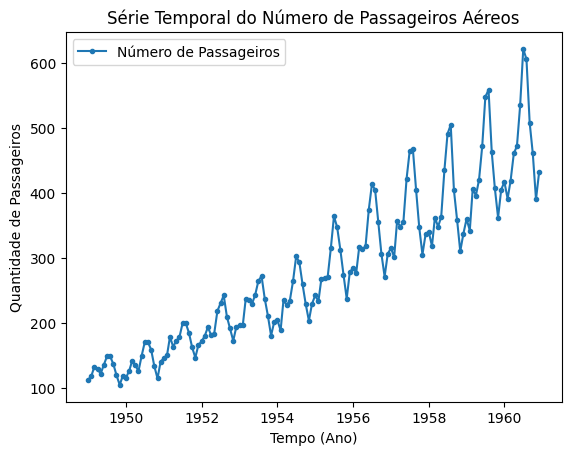

In [4]:
plt.plot(df, marker='o', markersize=3, label="Número de Passageiros")
plt.title("Série Temporal do Número de Passageiros Aéreos")
plt.xlabel("Tempo (Ano)")
plt.ylabel("Quantidade de Passageiros")
plt.savefig("serie_temporal_passageiros_visualization_datos.png", dpi=300, bbox_inches='tight')
plt.legend()

In [5]:
print(np.shape(df))
print(df.index.min())
print(df.index.max())

(144, 1)
1949-01-01 00:00:00
1960-12-01 00:00:00


## Data Preparation for LSTM

LSTM models require the data to be normalized and structured into input-output sequences. A sliding window approach is used, where the previous 12 observations are used to predict the next value.

In [6]:
# Normalize data
scaler = MinMaxScaler(feature_range=(0,1))
data_scaled = scaler.fit_transform(df.values)

# Create sequences
def create_dataset(data, time_step=12):
    X, y = [], []
    for i in range(len(data) - time_step):
        X.append(data[i:(i + time_step), 0])
        y.append(data[i + time_step, 0])
    return np.array(X), np.array(y)

time_step = 12  # one year window
X, y = create_dataset(data_scaled, time_step)

# Reshape for LSTM [samples, time steps, features]
X = X.reshape(X.shape[0], X.shape[1], 1)

### Seperate the data in test, train and validation datasets
A train/validation/test split is applied for methodological correctness, although limited data size affects statistical robustness.
70% of the data will be allocated for training, and 15% for testing and validation. 

In [7]:
# Train / validation / test split (time-ordered)
train_size = int(len(X) * 0.7)
val_size = int(len(X) * 0.15)

X_train = X[:train_size]
y_train = y[:train_size]

X_val = X[train_size:train_size + val_size]
y_val = y[train_size:train_size + val_size]

X_test = X[train_size + val_size:]
y_test = y[train_size + val_size:]

print("Train size:", X_train.shape)
print("Validation size:", X_val.shape)
print("Test size:", X_test.shape)

Train size: (92, 12, 1)
Validation size: (19, 12, 1)
Test size: (21, 12, 1)


### Illustration of the different Datasets

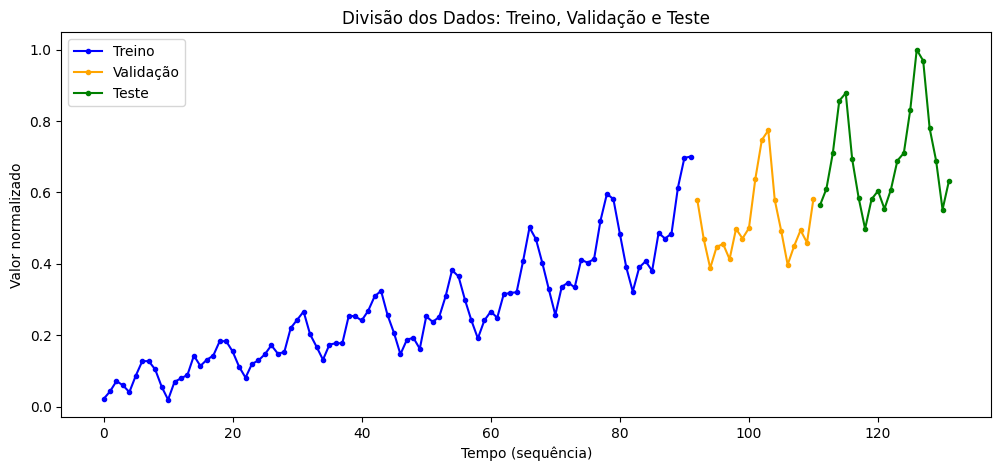

In [8]:
# Create index ranges for plotting (based on original sequence length)
train_size = len(X_train)
val_size = len(X_val)

plt.figure(figsize=(12,5))

# Plot train
plt.plot(range(0, train_size), y_train, marker='o', markersize=3, label="Treino", color="blue")

# Plot validation
plt.plot(range(train_size, train_size + val_size),
         y_val, label="Validação", marker='o', markersize=3, color="orange")

# Plot test
plt.plot(range(train_size + val_size, len(y)),
         y_test, label="Teste", marker='o', markersize=3, color="green")

plt.title("Divisão dos Dados: Treino, Validação e Teste")
plt.xlabel("Tempo (sequência)")
plt.ylabel("Valor normalizado")
plt.legend()
plt.savefig("serie_temporal_passageiros_data_splits.png", dpi=300, bbox_inches='tight')
plt.show()

## LSTM Model Construction and Training

An LSTM model is constructed using a single hidden layer followed by a dense output layer. The model is trained using the Adam optimizer and mean squared error loss function.

In [9]:
# Build model
model = Sequential()
model.add(LSTM(50, return_sequences=False, input_shape=(time_step, 1)))
model.add(Dense(1))

model.compile(optimizer='adam', loss='mean_squared_error')

# Train with validation set
history = model.fit(
    X_train, y_train,
    epochs=50,
    batch_size=16,
    validation_data=(X_val, y_val),
    verbose=1
)

Epoch 1/50


C:\01b_TUM\26_SoSe_MA4\TimeSeries\.venv\Lib\site-packages\keras\src\layers\rnn\rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


6/6 ━━━━━━━━━━━━━━━━━━━━ 2s 69ms/step - loss: 0.0578 - val_loss: 0.0756
Epoch 2/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - loss: 0.0154 - val_loss: 0.0126
Epoch 3/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - loss: 0.0106 - val_loss: 0.0241
Epoch 4/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - loss: 0.0095 - val_loss: 0.0130
Epoch 5/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - loss: 0.0062 - val_loss: 0.0145
Epoch 6/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - loss: 0.0069 - val_loss: 0.0145
Epoch 7/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - loss: 0.0063 - val_loss: 0.0131
Epoch 8/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - loss: 0.0058 - val_loss: 0.0165
Epoch 9/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - loss: 0.0057 - val_loss: 0.0167
Epoch 10/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - loss: 0.0054 - val_loss: 0.0141
Epoch 11/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - loss: 0.0052 - val_loss: 0.0156
Epoch 12/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - loss: 0.0051 - val_loss: 0.0177
Epoch 13/50


### Plot Training vs Validation Loss to Account for Overfitting

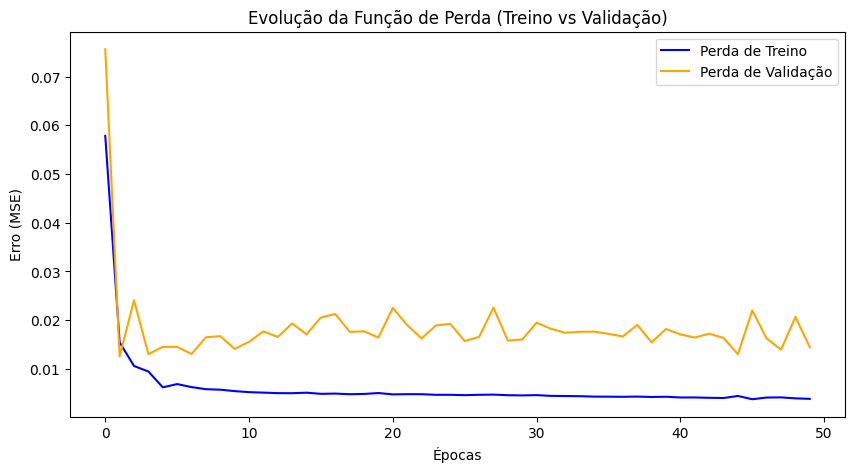

In [10]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10,5))
plt.plot(history.history['loss'], label="Perda de Treino", color="blue")
plt.plot(history.history['val_loss'], label="Perda de Validação", color="orange")

plt.title("Evolução da Função de Perda (Treino vs Validação)")
plt.xlabel("Épocas")
plt.ylabel("Erro (MSE)")
plt.legend()
plt.savefig("serie_temporal_passageiros_trainingProcess.png", dpi=300, bbox_inches='tight')
plt.show()

## Prediction and Results

After training, the model is used to generate predictions, which are then transformed back to the original scale for interpretation.

In [11]:
# Predict on test set
y_pred_train = model.predict(X_train)
y_pred_val = model.predict(X_val)
y_pred_test = model.predict(X_test)

# Inverse transform (back to original scale)
y_pred_train_inv = scaler.inverse_transform(y_pred_train)
y_train_inv = scaler.inverse_transform(y_train.reshape(-1,1))

y_pred_val_inv = scaler.inverse_transform(y_pred_val)
y_val_inv = scaler.inverse_transform(y_val.reshape(-1,1))

y_pred_test_inv = scaler.inverse_transform(y_pred_test)
y_test_inv = scaler.inverse_transform(y_test.reshape(-1,1))

3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 84ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step


## Visualization of Predictions

### Only for Test-Dataset
The predicted values are compared with the actual observations of the unknown test dataset to evaluate the model's performance visually.

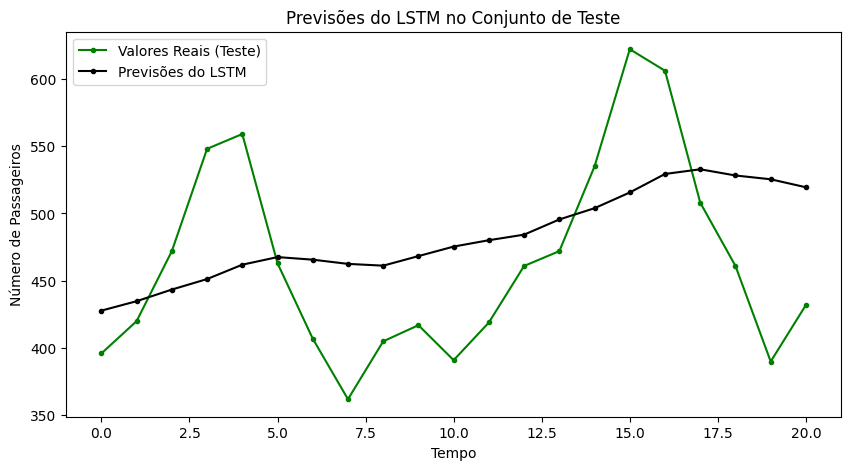

In [12]:
plt.figure(figsize=(10,5))

plt.plot(y_test_inv, marker='o', markersize=3, label="Valores Reais (Teste)", color="green")
plt.plot(y_pred_test_inv, marker='o', markersize=3, label="Previsões do LSTM", color="black")

plt.title("Previsões do LSTM no Conjunto de Teste")
plt.xlabel("Tempo")
plt.ylabel("Número de Passageiros")
plt.legend()
plt.savefig("serie_temporal_passageiros_previsionTestData.png", dpi=300, bbox_inches='tight')
plt.show()

In [13]:
rmse = np.sqrt(mean_squared_error(y_test_inv, y_pred_test_inv))
mae = mean_absolute_error(y_test_inv, y_pred_test_inv)

print("RMSE:", rmse)
print("MAE:", mae)

RMSE: 69.49599931192894
MAE: 60.078104654947914


### for Complete Dataset

In [14]:
time_index = df.index
time_index_aligned = time_index[time_step:]
t_train = time_index_aligned[:train_size]
t_val = time_index_aligned[train_size:train_size + val_size]
t_test = time_index_aligned[train_size + val_size:]



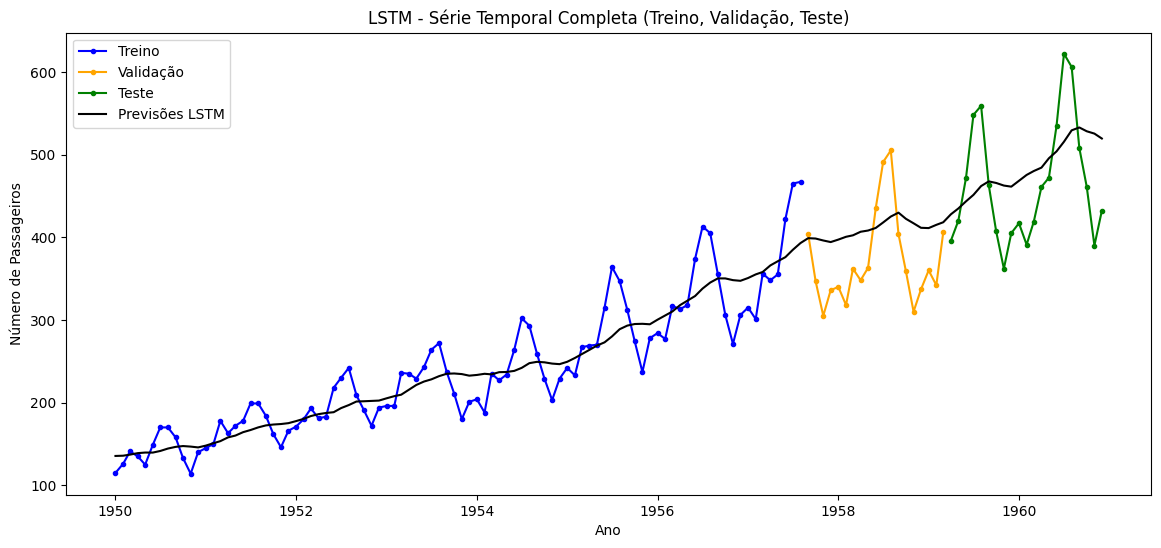

In [15]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14,6))

# TRAIN
plt.plot(t_train, y_train_inv, marker='o', markersize=3, label="Treino", color="blue")

# VALIDATION
plt.plot(t_val, y_val_inv, marker='o', markersize=3, label="Validação", color="orange")

# TEST (real values)
plt.plot(t_test, y_test_inv, marker='o', markersize=3, label="Teste", color="green")

# PREDICTIONS
plt.plot(time_index_aligned,np.concatenate([y_pred_train_inv, y_pred_val_inv, y_pred_test_inv]), label="Previsões LSTM", color="black")

plt.title("LSTM - Série Temporal Completa (Treino, Validação, Teste)")
plt.xlabel("Ano")
plt.ylabel("Número de Passageiros")
plt.legend()
plt.savefig("serie_temporal_passageiros_previsionAlldata.png", dpi=300, bbox_inches='tight')
plt.show()